# Chapitre 2 - Cours 3 : schémas souples et langages de requête

Le cours 1 a pesé la localité, le cours 2 les jointures. Restent deux arguments du débat
entre relationnel et documents : la **souplesse du schéma** et le **langage de requête**.
Ce cours couvre la fin de la section *Relational Versus Document Databases Today*
(*Which data model leads to simpler application code?*, *Schema flexibility in the
document model*, *Convergence of document and relational databases*) et la section
*Query Languages for Data* (*Declarative Queries on the Web*, *MapReduce Querying*).

**Plan.**

1. Quel modèle simplifie le code ?
2. Schéma à la lecture, schéma à l'écriture.
3. Déclaratif contre impératif.
4. Les requêtes déclaratives sur le Web.
5. MapReduce sur des documents.
6. Le pipeline d'agrégation.
7. La convergence des modèles.

In [1]:
import json
import sqlite3
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import datamodels as dm
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 90)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

## 1. Quel modèle simplifie le code ? (section *Which data model leads to simpler application code?*)

Le verdict du livre tient en deux phrases :

- si les données ont une **structure de document** (un arbre de relations un-à-plusieurs,
  chargé d'un bloc), le modèle document est probablement le bon choix. Le découpage
  relationnel d'un tel arbre en plusieurs tables, le *shredding*, donne des schémas
  lourds et du code inutilement compliqué (cours 1) ;
- si l'application a besoin de relations **plusieurs-à-plusieurs**, le modèle document
  perd son attrait : jointures émulées dans le code, dénormalisation à maintenir
  (cours 2). Et si ces relations dominent, le **graphe** devient le modèle naturel
  (cours 4).

Le modèle document a une autre limite, plus discrète : on ne peut pas désigner
**directement** un élément imbriqué. Il faut dire « le deuxième poste du profil 42 »,
une adresse **positionnelle** qui devient fausse dès que la liste change. En relationnel,
chaque poste a son propre identifiant stable. Démonstration : un autre service a retenu
l'adresse d'un poste pour y attacher une recommandation, puis l'utilisateur supprime un
ancien poste.

In [2]:
doc = {"user_id": 42, "positions": [
    {"job_title": "Architecte de données", "organization": "Datanet"},
    {"job_title": "Ingénieure logiciel", "organization": "Novasoft"},
    {"job_title": "Stagiaire", "organization": "Pixelsoft"}]}
rel = pd.DataFrame({"id": [9001, 9002, 9003], "user_id": 42,
                    "job_title": [p["job_title"] for p in doc["positions"]]})
adresse_doc = ("profil 42", "positions", 1)           # « le 2e poste du profil 42 »
adresse_rel = 9002                                    # l'identifiant du poste

del doc["positions"][0]                               # l'utilisateur supprime son poste le plus récent
rel = rel[rel.id != 9001]
pd.DataFrame({
    "référence": ["positions[1] dans le document", "positions.id = 9002"],
    "désignait": ["Ingénieure logiciel", "Ingénieure logiciel"],
    "désigne maintenant": [doc["positions"][adresse_doc[2]]["job_title"],
                           rel.loc[rel.id == adresse_rel, "job_title"].item()],
})

,référence,désignait,désigne maintenant
0,positions[1] dans le document,Ingénieure logiciel,Stagiaire
1,positions.id = 9002,Ingénieure logiciel,Ingénieure logiciel


La référence positionnelle pointe désormais sur le **mauvais** poste, sans aucune erreur.
Le remède est d'attribuer un identifiant à chaque élément imbriqué, ce qui revient à
réintroduire une idée relationnelle dans le document.

> **À retenir.** Arbre lu d'un bloc : modèle document. Relations plusieurs-à-plusieurs :
> relationnel, ou graphe si elles dominent. Un élément imbriqué dans un document n'a pas
> d'adresse stable sans identifiant propre.

## 2. Schéma à la lecture, schéma à l'écriture (section *Schema flexibility in the document model*)

Les bases documents, et le support JSON des bases relationnelles, n'imposent en général
**aucun schéma** : on peut ajouter n'importe quelle clé à un document, et le lecteur n'a
aucune garantie sur les champs présents. On les dit *schemaless*, ce qui est trompeur :
le code qui lit les données suppose bien une structure. Il existe un schéma **implicite**,
que la base ne vérifie pas. Le livre préfère parler de :

- **schéma à la lecture** (*schema-on-read*) : la structure est interprétée au moment
  où l'on lit, comme le typage **dynamique** d'un langage ;
- **schéma à l'écriture** (*schema-on-write*) : la base vérifie à chaque écriture que
  les données respectent le schéma déclaré, comme le typage **statique**.

La différence saute aux yeux quand le format change. Exemple du livre : on stockait le
nom complet dans un seul champ `name`, on veut désormais un champ `first_name` séparé.

**Schéma à l'écriture** : on migre la table. Ajouter une colonne avec une valeur par
défaut `NULL` est quasi instantané dans la plupart des bases ; mais remplir la colonne
(`UPDATE`) réécrit **chaque ligne**. Mesurons les deux étapes sur SQLite pour des tables
de taille croissante.

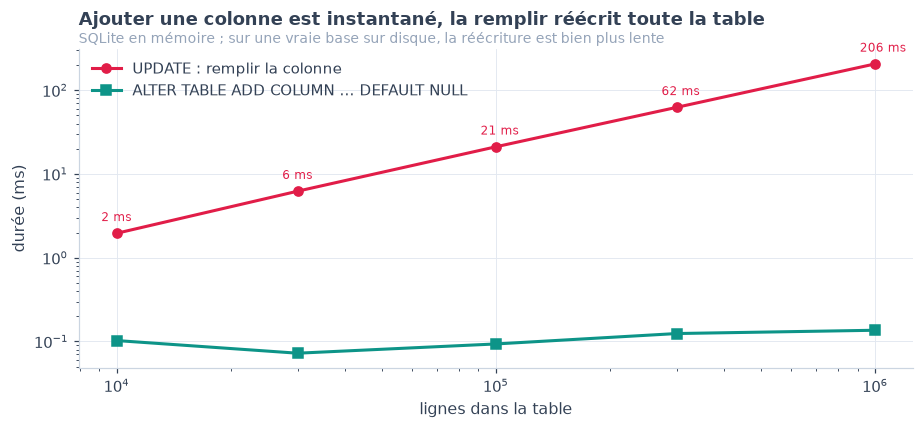

,lignes,ALTER (ms),UPDATE (ms)
0,10000,0.10,1.96
1,30000,0.07,6.22
2,100000,0.09,21.09
3,300000,0.12,62.43
4,1000000,0.14,205.93


In [3]:
def migration_cost(n):
    c = sqlite3.connect(":memory:")
    c.execute("CREATE TABLE users (id INTEGER PRIMARY KEY, name TEXT, bio TEXT)")
    c.executemany("INSERT INTO users VALUES (?, ?, ?)",
                  ((i, f"Prénom{i % 997} Nom{i}", "x" * 60) for i in range(n)))
    c.commit()
    t0 = time.perf_counter()
    c.execute("ALTER TABLE users ADD COLUMN first_name TEXT DEFAULT NULL")
    t_alter = time.perf_counter() - t0
    t0 = time.perf_counter()
    c.execute("UPDATE users SET first_name = substr(name, 1, instr(name, ' ') - 1)")
    c.commit()
    t_update = time.perf_counter() - t0
    assert c.execute("SELECT first_name FROM users WHERE id = 5").fetchone()[0] == "Prénom5"
    return t_alter * 1e3, t_update * 1e3

tailles = [10_000, 30_000, 100_000, 300_000, 1_000_000]
mig = pd.DataFrame([(n, *migration_cost(n)) for n in tailles], columns=["lignes", "ALTER (ms)", "UPDATE (ms)"])

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.loglog(mig["lignes"], mig["UPDATE (ms)"], marker="o", color=ROSE, label="UPDATE : remplir la colonne")
ax.loglog(mig["lignes"], mig["ALTER (ms)"], marker="s", color=TEAL, label="ALTER TABLE ADD COLUMN ... DEFAULT NULL")
for x, y in zip(mig["lignes"], mig["UPDATE (ms)"]):
    ax.annotate(f"{y:.0f} ms", (x, y), (-10, 8), textcoords="offset points", fontsize=8, color=ROSE)
ax.set_xlabel("lignes dans la table"); ax.set_ylabel("durée (ms)")
ax.set_title("Ajouter une colonne est instantané, la remplir réécrit toute la table")
subtitle(ax, "SQLite en mémoire ; sur une vraie base sur disque, la réécriture est bien plus lente")
ax.legend(); plt.tight_layout(); plt.show()
mig.round(2)

L'`ALTER TABLE` reste sous la milliseconde quelle que soit la taille (SQLite ne fait que
modifier le schéma enregistré), tandis que l'`UPDATE` croît linéairement. Sur une base de
production de plusieurs téraoctets, cette réécriture prend des heures, verrouille ou
alourdit la table et génère un énorme volume de journal ; des outils existent pour
migrer en arrière-plan sans interruption, mais l'opération reste délicate. On peut
l'éviter en ajoutant la colonne à `NULL` et en la remplissant **à la lecture**... ce qui
revient à faire du schéma à la lecture dans une base relationnelle.

**Schéma à la lecture** : on écrit simplement les nouveaux documents avec le nouveau
champ, et le code de lecture traite les anciens :

In [4]:
def read_user(user):
    """Lecteur tolérant : les documents écrits avant la migration n'ont pas first_name."""
    if user and user.get("name") and not user.get("first_name"):
        user = dict(user, first_name=user["name"].split(" ")[0])
    return user

print(read_user({"name": "Inès Martin"}))
print(read_user({"name": "Inès Martin", "first_name": "Inès"}))

{'name': 'Inès Martin', 'first_name': 'Inès'}
{'name': 'Inès Martin', 'first_name': 'Inès'}


L'inconvénient : **chaque** partie de l'application qui lit ces documents doit gérer
**tous** les formats passés, potentiellement écrits il y a des années. Simulons la vie
d'une collection de 100 000 documents sur huit ans, avec un changement de format par an.
Un document n'est réécrit au format courant que lorsqu'il est modifié (ici, 30 % des
documents par an), et de nouveaux documents arrivent.

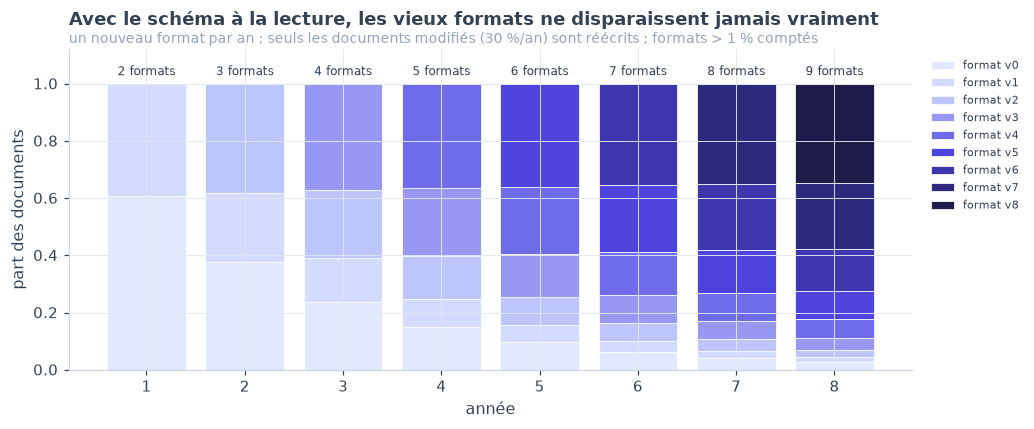

In [5]:
n_docs, years = 100_000, 8
version = np.zeros(n_docs, dtype=int)
hist = []
for y in range(1, years + 1):
    touched = rng.random(version.size) < 0.30
    version[touched] = y
    version = np.concatenate([version, np.full(15_000, y)])
    hist.append(np.bincount(version, minlength=years + 1))
hist = np.array(hist)

fig, ax = plt.subplots(figsize=(9.5, 4))
bottom = np.zeros(years)
cmap = plt.get_cmap("ddia_seq")
for v in range(years + 1):
    frac = hist[:, v] / hist.sum(axis=1)
    ax.bar(np.arange(1, years + 1), frac, bottom=bottom, color=cmap(0.15 + 0.85 * v / years),
           edgecolor="white", lw=0.5, label=f"format v{v}")
    bottom += frac
for y in range(years):
    n_formats = (hist[y] > 0.01 * hist[y].sum()).sum()
    ax.text(y + 1, 1.03, f"{n_formats} formats", ha="center", fontsize=8, color=SLATE)
ax.set_xlabel("année"); ax.set_ylabel("part des documents"); ax.set_ylim(0, 1.12)
ax.set_title("Avec le schéma à la lecture, les vieux formats ne disparaissent jamais vraiment")
subtitle(ax, "un nouveau format par an ; seuls les documents modifiés (30 %/an) sont réécrits ; formats > 1 % comptés")
ax.legend(fontsize=7.5, loc="upper left", bbox_to_anchor=(1.01, 1.0)); plt.tight_layout(); plt.show()

Après huit ans, les neuf formats successifs pèsent encore chacun plus de 1 % des
documents : le code de lecture doit tous les comprendre. Le schéma à l'écriture concentre ce coût dans la migration ; le schéma à
la lecture le dilue dans tout le code, pour toujours.

**Quand le schéma à la lecture l'emporte-t-il ?** Quand les données sont
**hétérogènes** : de nombreux types d'objets qu'il serait absurde de ranger chacun dans
sa table, ou une structure dictée par des **systèmes externes** qui peuvent la changer à
tout moment. Exemple : des événements reçus de trois fournisseurs de paiement.

In [6]:
fournisseurs = {
    "A": lambda i: {"id": i, "amount": 10.0, "currency": "EUR", "status": "ok"},
    "B": lambda i: {"txn": i, "amount_cents": 1000, "meta": {"country": "FR"}, "state": "SETTLED"},
    "C": lambda i: {"id": i, "value": {"amount": "10.00", "ccy": "EUR"}, "events": ["created", "paid"],
                    **({"refund": True} if i % 7 == 0 else {})},
}
evts = [fournisseurs[f](i) for i in range(3000) for f in "ABC" if rng.random() < 0.6]
formes = Counter(tuple(sorted(e)) for e in evts)
pd.DataFrame({"ensemble de clés": [", ".join(k) for k in formes], "documents": list(formes.values())})

,ensemble de clés,documents
0,"amount, currency, id, status",1830
1,"amount_cents, meta, state, txn",1845
2,"events, id, refund, value",243
3,"events, id, value",1507


Quatre « formes » différentes coexistent (le fournisseur C ajoute un champ `refund`
certains jours) : un schéma relationnel strict demanderait une table par forme, et une
migration à chaque caprice d'un fournisseur. Ici, des documents sans schéma sont plus
naturels. Mais quand tous les enregistrements ont la même structure, un schéma est un
excellent moyen de la **documenter** et de la **faire respecter**. Nous reviendrons sur
l'évolution des schémas au chapitre 4.

> **À retenir.** « Sans schéma » signifie « schéma implicite, vérifié à la lecture ». Le
> schéma à l'écriture paie le changement de format en une migration (rapide pour
> ajouter une colonne, lente pour réécrire les lignes) ; le schéma à la lecture le paie
> dans tout le code lecteur, indéfiniment. Il gagne pour les données hétérogènes.